# Практика по лекции 1: EDA, визуализация, пропуски и выбросы

**Цель:** научиться проводить первичный анализ временного ряда и готовить его к моделированию.

**Данные.** Реальных данных нет, поэтому ряд генерируется функцией `generate_time_series` из лабораторной работы
(тренд + две сезонности + шум), после чего в него добавляются **пропуски** и **выбросы** (как разрешено в лекции).
Шаг ряда — 5 минут, длина — 10 суток (2880 точек).

In [1]:
import os
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## Подготовка данных

### Генератор из лабораторной работы 1

In [2]:
STEP_MINUTES = 5
PERIOD_1H = 12   # 1 час при шаге 5 минут
PERIOD_6H = 72   # 6 часов при шаге 5 минут

VARIANCE_MODES = ["const", "grow", "decay"]
TREND_MODES = ["none", "fast_up", "slow_up", "fast_down", "slow_down"]
SEASONALITY_MODES = ["none", "one", "two"]

# Суммарное изменение тренда за весь ряд
TREND_TOTAL = {"fast_up": 60.0, "slow_up": 15.0, "fast_down": -60.0, "slow_down": -15.0}


def _unique_path(path):
    if not os.path.exists(path):
        return path
    root, ext = os.path.splitext(path)
    i = 1
    while os.path.exists(f"{root}_{i}{ext}"):
        i += 1
    return f"{root}_{i}{ext}"


def generate_time_series(
    n_points=1000,
    variance="const",
    trend="none",
    seasonality="none",
    base=100.0,
    noise_std=2.0,
    seed=None,
    save_csv=True,
    csv_dir=".",
    save_plot=False,
    plot_path=None,
    show_plot=True,
):
    if n_points < 1:
        raise ValueError("n_points должно быть >= 1")

    rng = np.random.default_rng(seed)

    # Случайный выбор режимов
    if variance == "random":
        variance = str(rng.choice(VARIANCE_MODES))
    if trend == "random":
        trend = str(rng.choice(TREND_MODES))
    if seasonality == "random":
        seasonality = str(rng.choice(SEASONALITY_MODES))

    if variance not in VARIANCE_MODES:
        raise ValueError(f"Неизвестный режим дисперсии: {variance}")
    if trend not in TREND_MODES:
        raise ValueError(f"Неизвестный режим тренда: {trend}")
    if seasonality not in SEASONALITY_MODES:
        raise ValueError(f"Неизвестный режим сезонности: {seasonality}")

    # временная ось: с 00:00 текущего дня, шаг 5 минут
    start = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start + timedelta(minutes=STEP_MINUTES * i) for i in range(n_points)]

    idx = np.arange(n_points)
    progress = idx / max(n_points - 1, 1)

    # тренд
    trend_values = np.zeros(n_points) if trend == "none" else TREND_TOTAL[trend] * progress

    # сезонность
    season_values = np.zeros(n_points)
    if seasonality in ("one", "two"):
        season_values += 10.0 * np.sin(2 * np.pi * idx / PERIOD_1H)
    if seasonality == "two":
        season_values += 20.0 * np.sin(2 * np.pi * idx / PERIOD_6H)

    # дисперсия:
    if variance == "const":
        sigma = np.full(n_points, noise_std)
    elif variance == "grow":
        sigma = noise_std * (0.25 + 3.75 * progress)
    else:
        sigma = noise_std * (4.0 - 3.75 * progress)

    noise = rng.normal(0.0, 1.0, n_points) * sigma

    values = base + trend_values + season_values + noise
    params = {"n_points": n_points, "variance": variance, "trend": trend,
              "seasonality": seasonality, "seed": seed}

    if save_csv:
        name = "ts_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
        path = _unique_path(os.path.join(csv_dir, name))
        with open(path, "w", encoding="utf-8") as f:
            f.write("timestamp,value\n")
            for t, v in zip(timestamps, values):
                f.write(f"{t:%Y-%m-%d %H:%M:%S},{v:.6f}\n")
        params["csv_file"] = path

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(timestamps, values, lw=0.9)
    ax.set_title(f"variance={variance}, trend={trend}, seasonality={seasonality}, n={n_points}")
    ax.set_xlabel("Время")
    ax.set_ylabel("Значение")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()

    if save_plot:
        if plot_path is None:
            raise ValueError("Укажите plot_path для сохранения графика")
        os.makedirs(os.path.dirname(plot_path) or ".", exist_ok=True)
        fig.savefig(plot_path, dpi=150)
        params["plot_file"] = plot_path

    if show_plot:
        plt.show()
    else:
        plt.close(fig)

    return timestamps, values, params

### Генерация ряда и порча данных

1. Ряд: медленный рост, две сезонности (1 ч и 6 ч), постоянная дисперсия.
2. Выбросы: 6 одиночных скачков величиной 35–60 единиц (при σ шума ≈ 2).
3. Пропуски: 40 одиночных точек и три «куска» подряд (3, 12 и 60 точек).
4. В файл `series.csv` строки пишутся **в случайном порядке** и с **тремя дубликатами** — чтобы шаг 1 был не формальным.

Истинные позиции выбросов сохраняются в `true_outlier_ts` **только для проверки** качества детекции в конце (в реальных данных такой разметки нет).

In [3]:
N = 2880  # 10 суток при шаге 5 минут
ts, vals, params = generate_time_series(
    n_points=N, variance="const", trend="slow_up", seasonality="two",
    seed=42, save_csv=False, show_plot=False,
)
print(params)

rng = np.random.default_rng(7)
clean = np.asarray(vals, dtype=float)

# пропуски: одиночные + три блока
missing = np.zeros(N, dtype=bool)
missing[rng.choice(N, size=40, replace=False)] = True
for start, length in [(500, 3), (1400, 12), (2100, 60)]:
    missing[start:start + length] = True

# выбросы: только в местах, где значение есть
free = np.flatnonzero(~missing)
free = free[(free > 100) & (free < N - 100)]
outlier_idx = np.sort(rng.choice(free, size=6, replace=False))
shifts = rng.choice([-1, 1], size=6) * rng.uniform(35, 60, size=6)

dirty = clean.copy()
dirty[outlier_idx] += shifts
true_outlier_ts = pd.DatetimeIndex([ts[i] for i in outlier_idx])  # только для проверки в конце

# запись в CSV: пропущенные строки отсутствуют, порядок перемешан, есть дубликаты
rows = [(ts[i], dirty[i]) for i in range(N) if not missing[i]]
dups = [rows[j] for j in rng.choice(len(rows), size=3, replace=False)]
rows = rows + dups
order = rng.permutation(len(rows))
with open("series.csv", "w", encoding="utf-8") as f:
    f.write("timestamp,y\n")
    for k in order:
        t, v = rows[k]
        f.write(f"{t:%Y-%m-%d %H:%M:%S},{v:.6f}\n")
print("series.csv записан, строк:", len(rows))

{'n_points': 2880, 'variance': 'const', 'trend': 'slow_up', 'seasonality': 'two', 'seed': 42}
series.csv записан, строк: 2768


## 1. Загрузка данных

Парсим время, сортируем, проверяем и убираем дубликаты.

In [4]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"])
print("Строк в файле:          ", len(df))
print("Упорядочен по времени:  ", df["timestamp"].is_monotonic_increasing)
print("Дубликатов timestamp:   ", df["timestamp"].duplicated().sum())

df = df.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")
print("После очистки строк:    ", len(df))
print("Диапазон:", df.index.min(), "…", df.index.max())
df.head()

Строк в файле:           2768
Упорядочен по времени:   False
Дубликатов timestamp:    3
После очистки строк:     2765
Диапазон: 2026-11-20 00:00:00 … 2026-11-29 23:55:00


,y
timestamp,
2026-11-20 00:00:00,100.609434
2026-11-20 00:05:00,104.668357
2026-11-20 00:10:00,113.644540
2026-11-20 00:15:00,117.073141
2026-11-20 00:20:00,111.619427


## 2. Временной индекс и проверка частоты

Смотрим, какие шаги встречаются между соседними наблюдениями, затем приводим ряд к регулярной сетке 5 минут.

In [5]:
steps = df.index.to_series().diff().dropna()
print("Шаги между наблюдениями (сколько раз встречается):")
print(steps.value_counts().head(6).to_string())

full_idx = pd.date_range(df.index.min(), df.index.max(), freq="5min")
print("\nОжидается точек:", len(full_idx), "| есть:", len(df), "| не хватает:", len(full_idx) - len(df))

df = df.reindex(full_idx)      # то же, что asfreq("5min")
df.index.name = "timestamp"
print("Пропусков (NaN) после приведения к сетке:", df["y"].isna().sum())
df.describe().T

Шаги между наблюдениями (сколько раз встречается):
timestamp
0 days 00:05:00    2722
0 days 00:10:00      38
0 days 00:20:00       1
0 days 01:05:00       1
0 days 05:05:00       1
0 days 00:15:00       1

Ожидается точек: 2880 | есть: 2765 | не хватает: 115
Пропусков (NaN) после приведения к сетке: 115


,count,mean,std,min,25%,50%,75%,max
y,2765.0,107.38658,16.589121,38.463068,94.537358,107.449114,120.420781,171.337061


## 3. Графики

### 3.1 Весь ряд

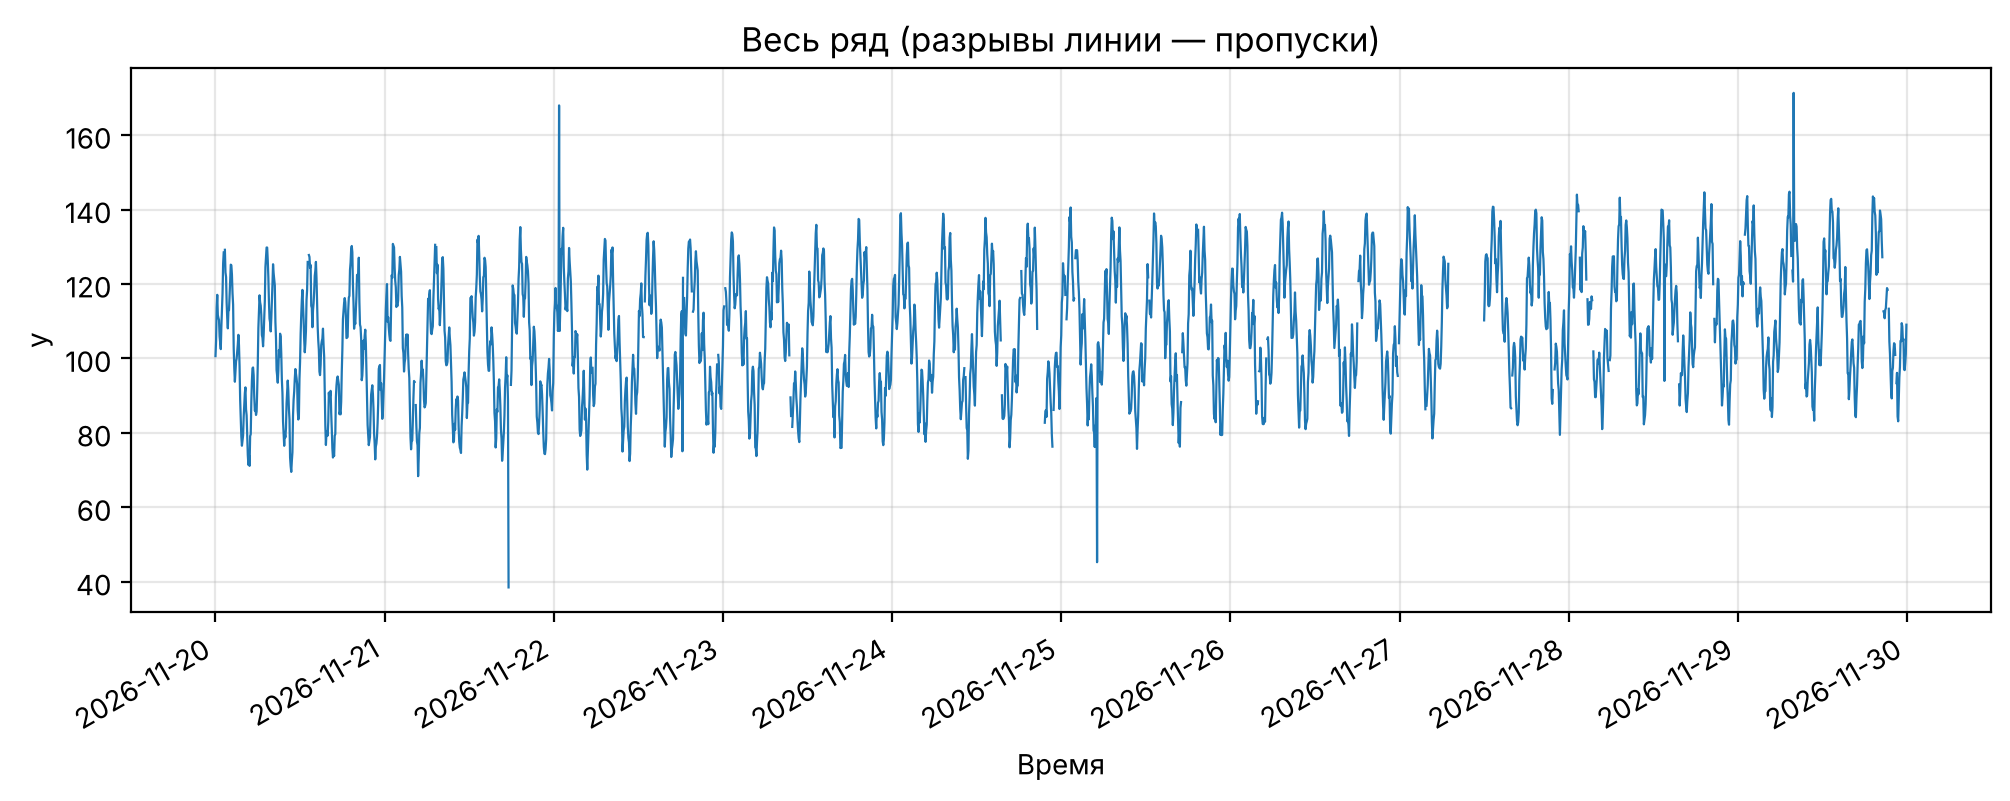

In [6]:
fig, ax = plt.subplots()
ax.plot(df.index, df["y"], lw=0.8)
ax.set_title("Весь ряд (разрывы линии — пропуски)")
ax.set_xlabel("Время"); ax.set_ylabel("y")
fig.autofmt_xdate(); plt.show()

### 3.2 Увеличенные фрагменты

Слева — одни сутки, справа — 6 часов (один период длинной сезонности).

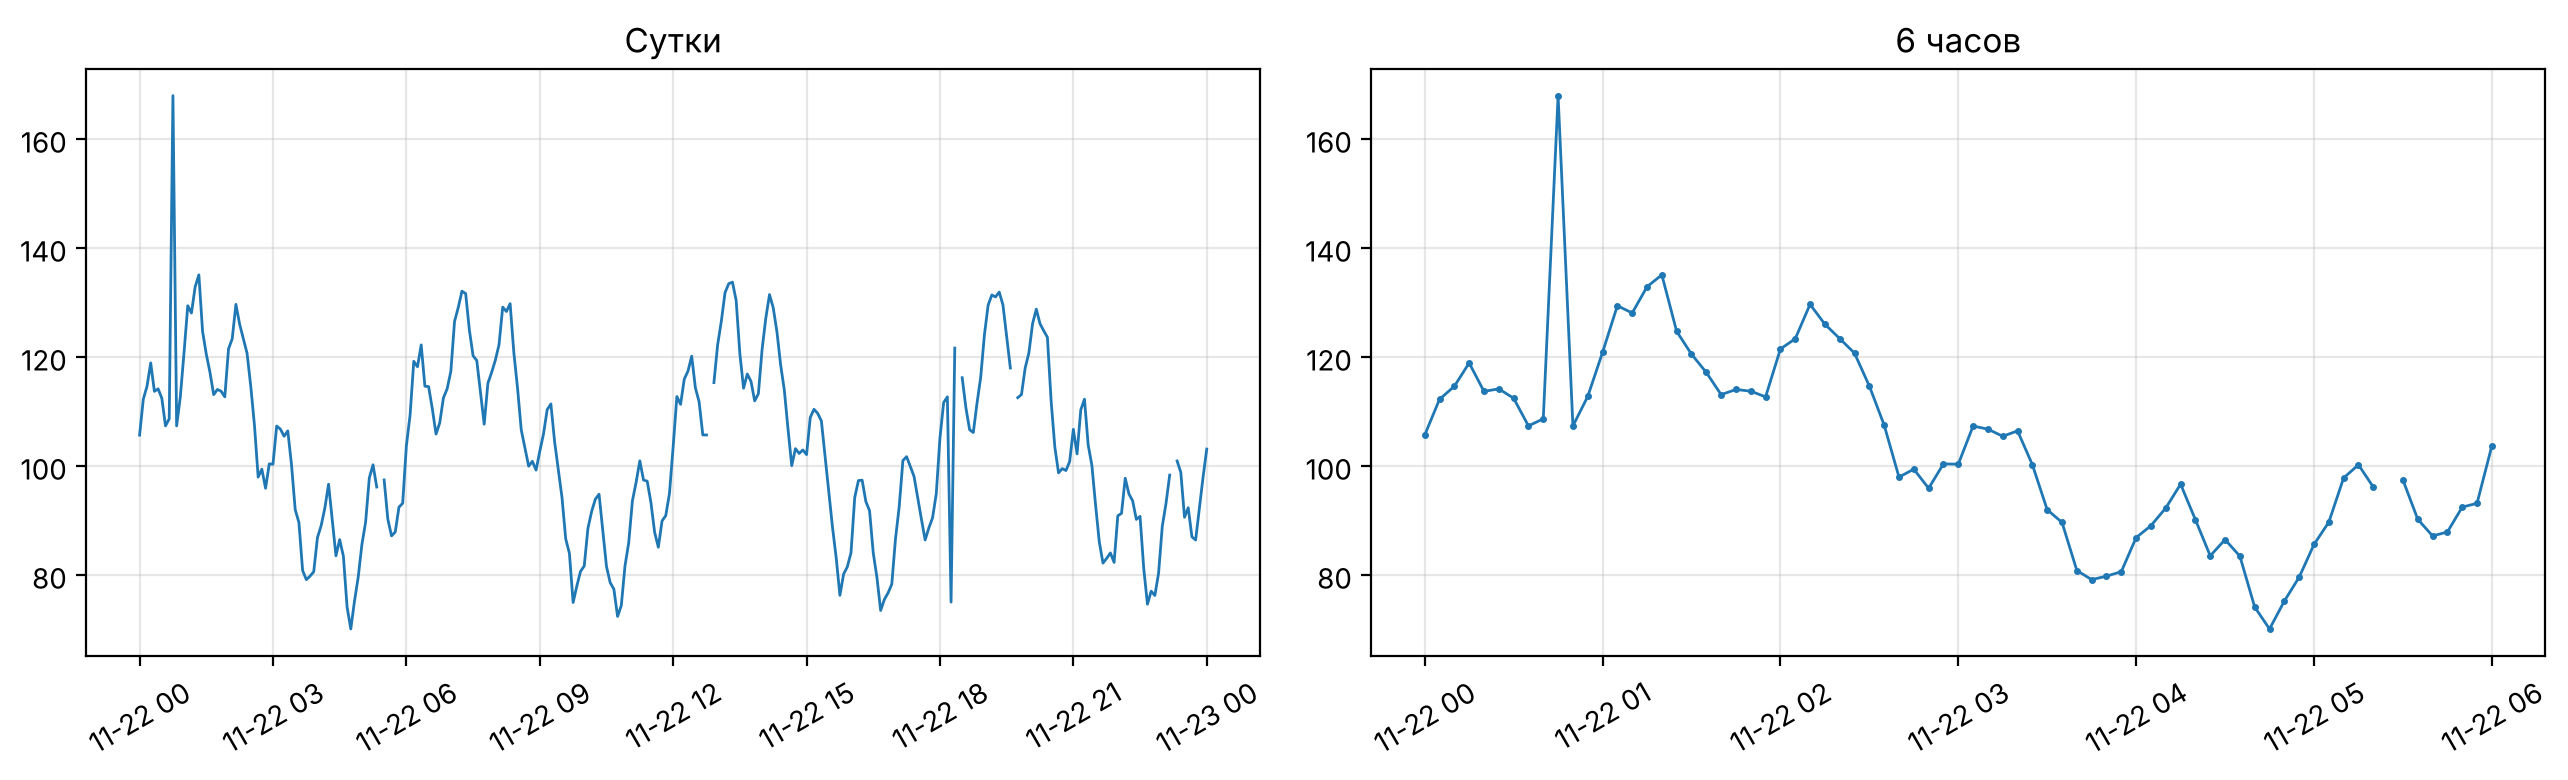

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
d0 = df.index[0].normalize() + pd.Timedelta(days=2)
day = df.loc[d0: d0 + pd.Timedelta(days=1)]
six = df.loc[d0: d0 + pd.Timedelta(hours=6)]
axes[0].plot(day.index, day["y"], lw=1); axes[0].set_title("Сутки")
axes[1].plot(six.index, six["y"], lw=1, marker=".", ms=3); axes[1].set_title("6 часов")
for a in axes:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 3.3 Скользящее среднее и скользящее стандартное отклонение

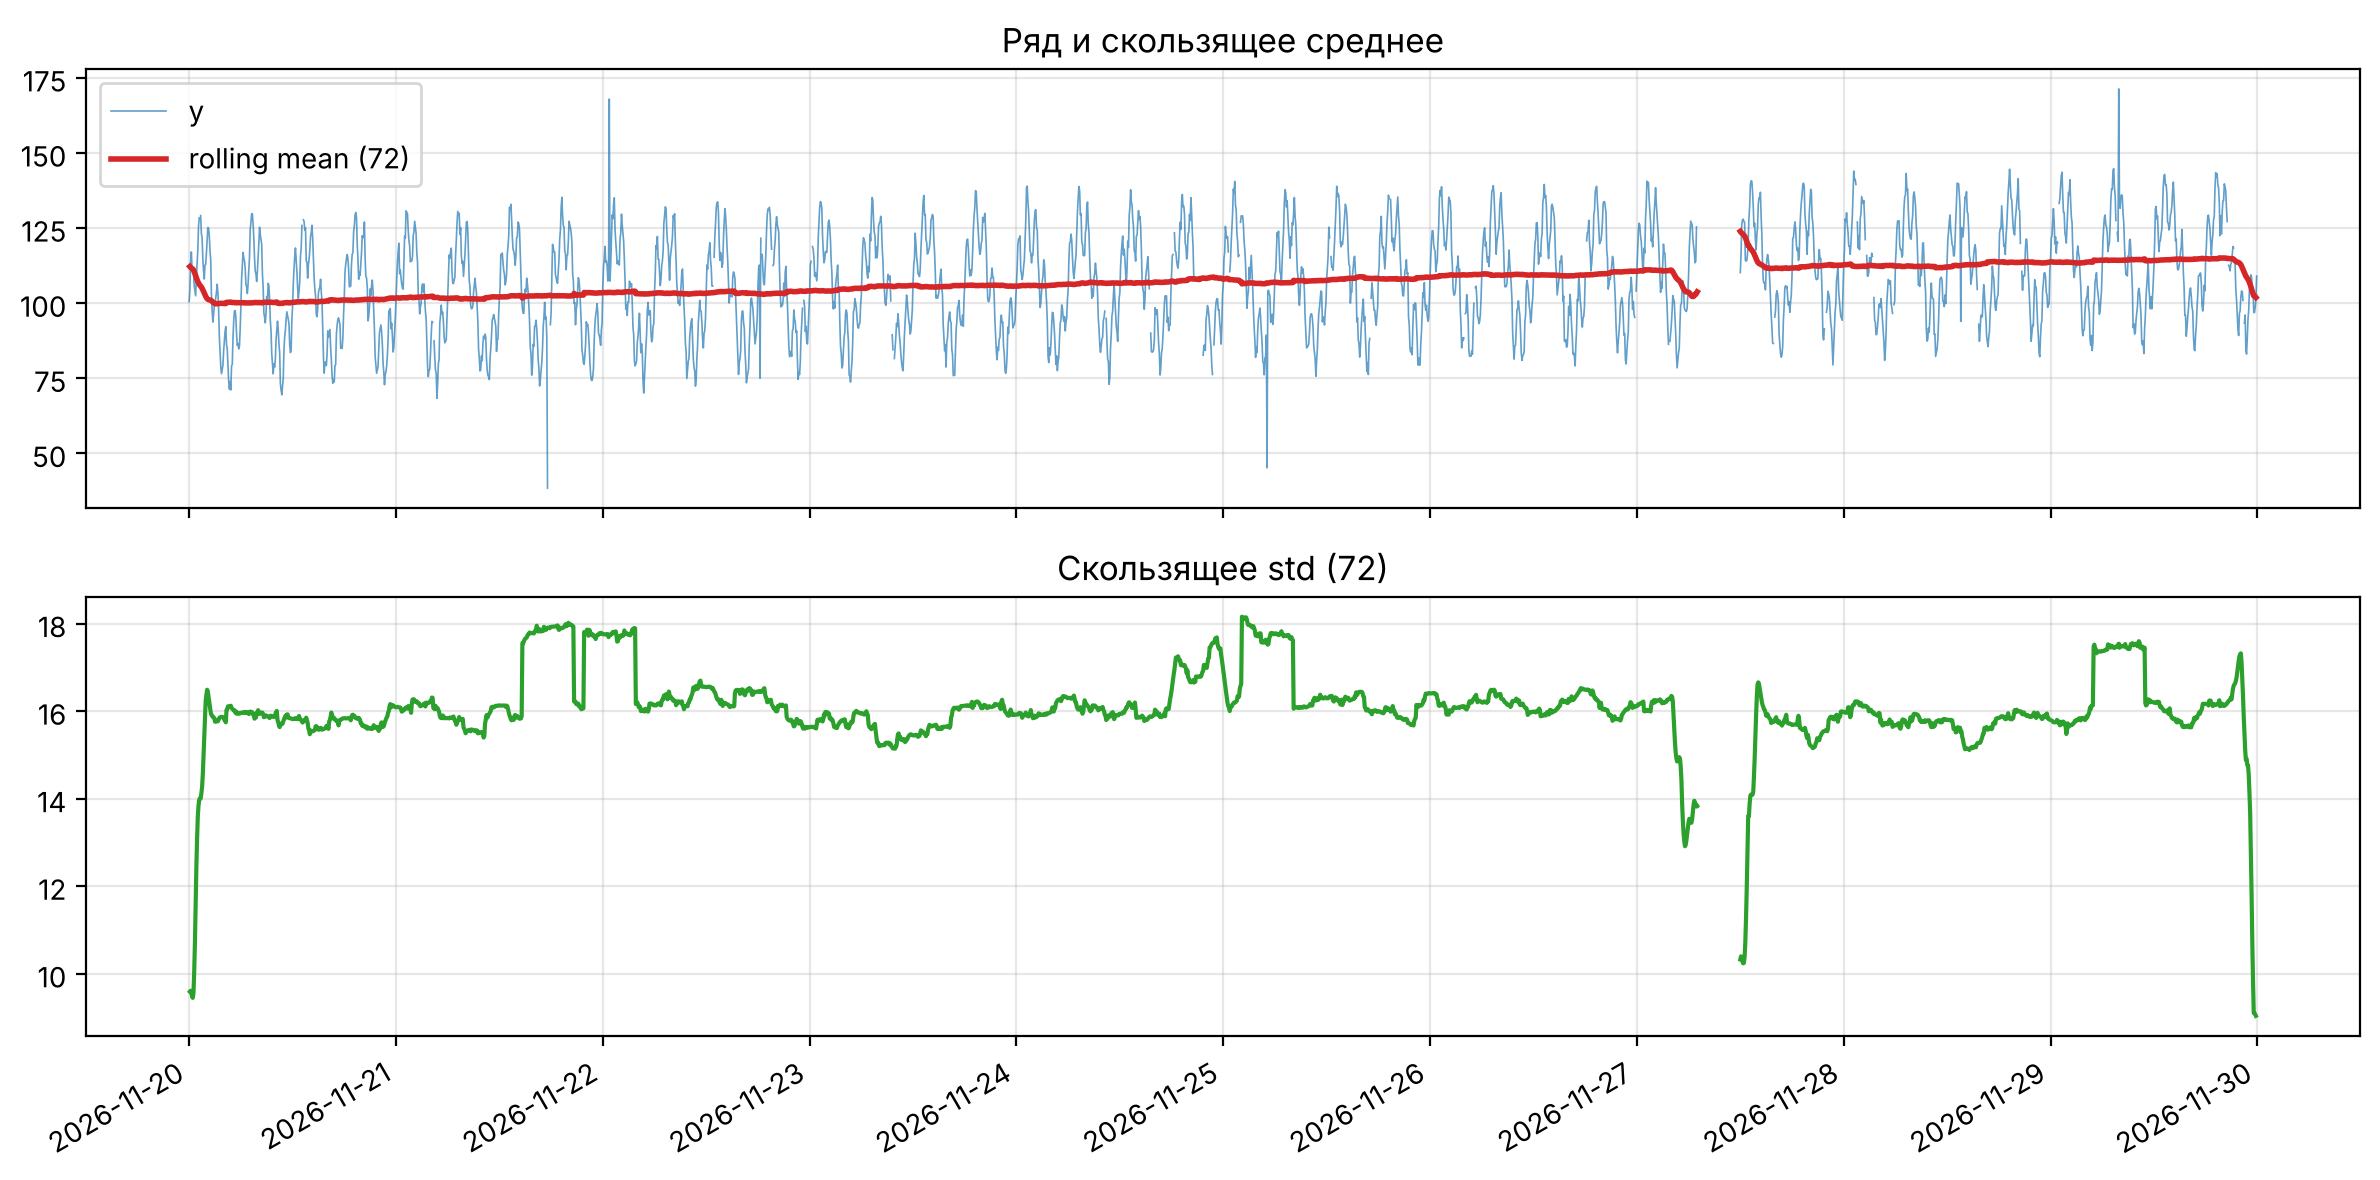

Среднее по суткам (за сутки обе сезонности сокращаются, остаётся тренд):
timestamp
2026-11-20    100.5
2026-11-21    102.1
2026-11-22    103.6
2026-11-23    105.4
2026-11-24    106.8
2026-11-25    107.7
2026-11-26    109.6
2026-11-27    112.1
2026-11-28    112.8
2026-11-29    114.3
Freq: D

Рост между первыми и последними сутками: 13.8
Скользящее std: медиана 16.0, 5%-квантиль 15.3, 95%-квантиль 17.8


In [8]:
W = 72
df["rolling_mean"] = df["y"].rolling(W, min_periods=W // 2, center=True).mean()
df["rolling_std"] = df["y"].rolling(W, min_periods=W // 2, center=True).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(df.index, df["y"], lw=0.6, label="y", alpha=0.7)
axes[0].plot(df.index, df["rolling_mean"], lw=2, color="C3", label=f"rolling mean ({W})")
axes[0].legend(); axes[0].set_title("Ряд и скользящее среднее")
axes[1].plot(df.index, df["rolling_std"], color="C2")
axes[1].set_title(f"Скользящее std ({W})")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

daily = df["y"].resample("D").mean()
print("Среднее по суткам (за сутки обе сезонности сокращаются, остаётся тренд):")
print(daily.round(1).to_string())
print("\nРост между первыми и последними сутками: %.1f" % (daily.iloc[-1] - daily.iloc[0]))
q = df["rolling_std"].quantile([0.05, 0.5, 0.95])
print("Скользящее std: медиана %.1f, 5%%-квантиль %.1f, 95%%-квантиль %.1f" % (q[0.5], q[0.05], q[0.95]))

### 3.4 Сезонные подсерии

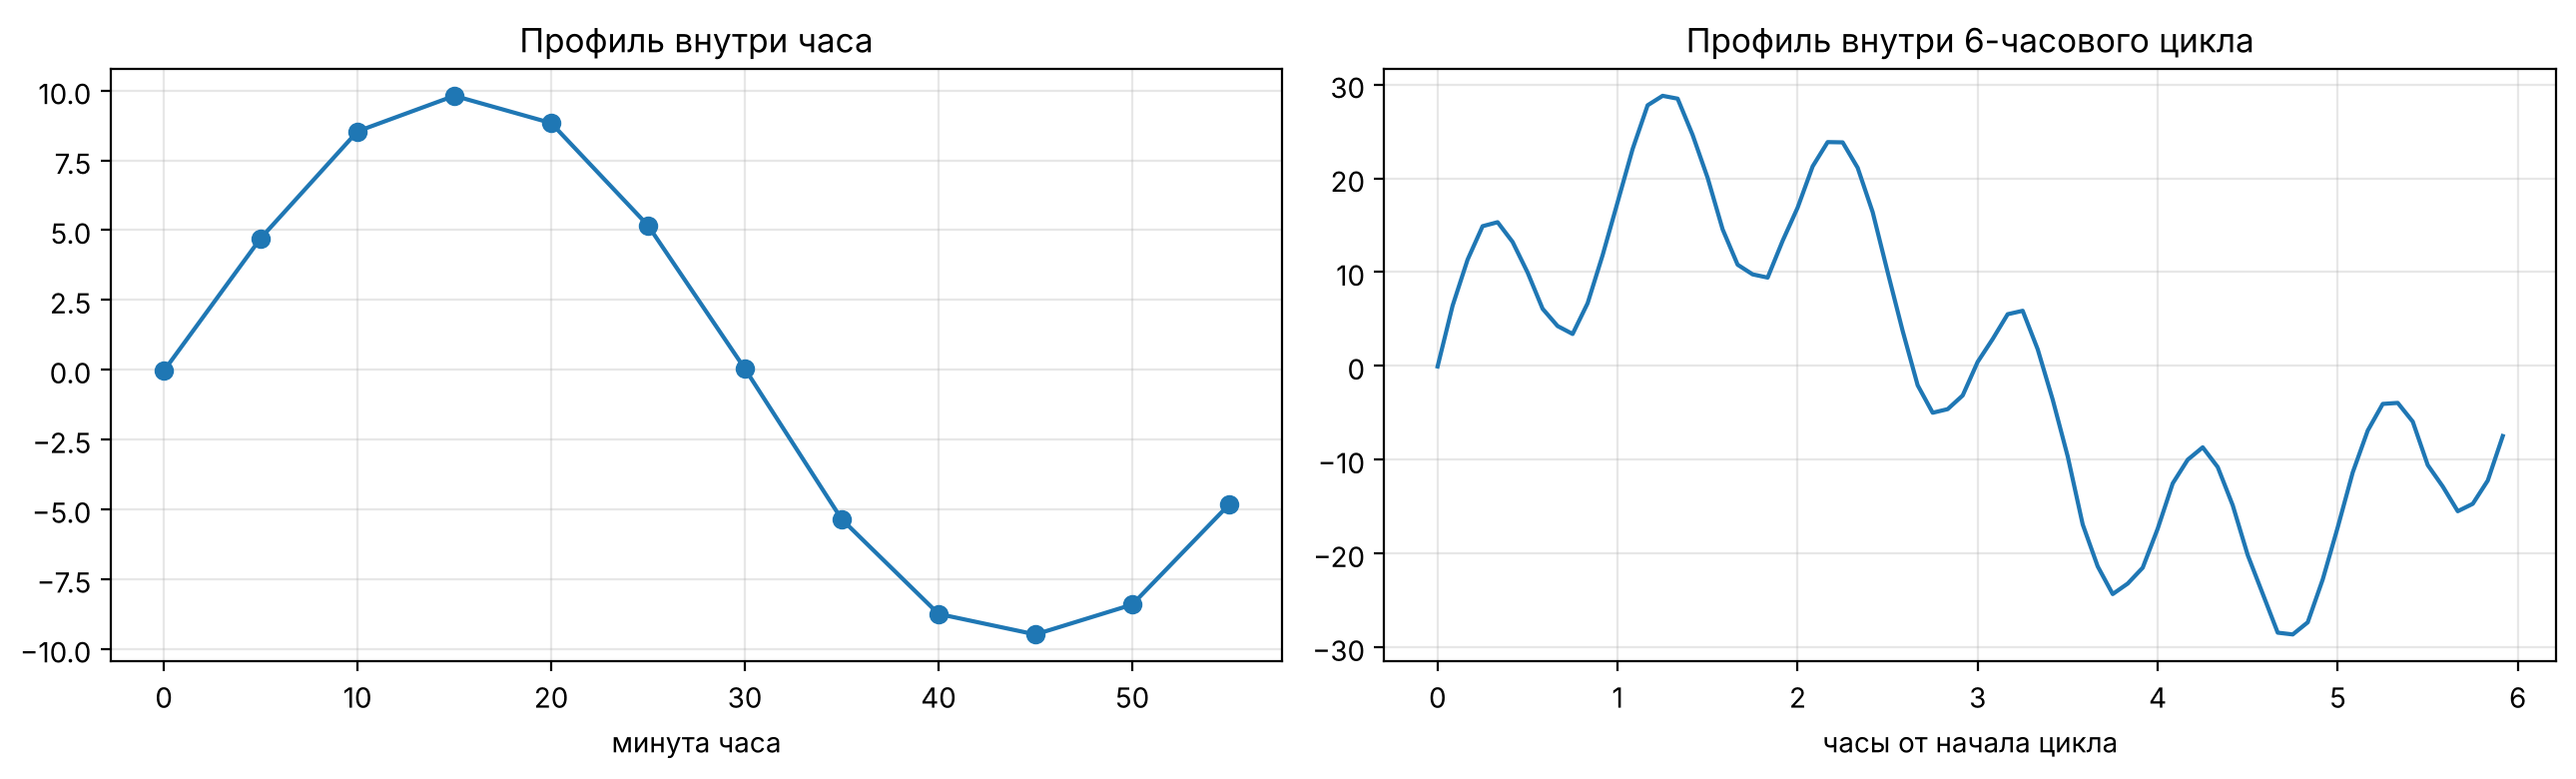

In [9]:
detr = df["y"] - df["rolling_mean"]
slot = ((df.index - df.index.normalize()).total_seconds() // 300).astype(int)   # номер 5-минутного слота в сутках
pos12 = slot % 12
pos72 = slot % 72

prof12 = detr.groupby(pos12).mean()      # по 6 фазам длинного цикла его вклад в среднем сокращается
prof72 = detr.groupby(pos72).median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(prof12.index * 5, prof12.values, marker="o")
axes[0].set_title("Профиль внутри часа"); axes[0].set_xlabel("минута часа")
axes[1].plot(prof72.index * 5 / 60, prof72.values)
axes[1].set_title("Профиль внутри 6-часового цикла"); axes[1].set_xlabel("часы от начала цикла")
plt.tight_layout(); plt.show()

### 3.5 Heatmap «дата × час суток»

Средние значения по часам. Аналог «час × день недели» из лекции (недели у нас нет). Белая область — пропуск 27.11 (5 часов). Тёмная ячейка 24.11 в 21:00 получилась из-за пропуска: среднее взято по неполному часу.

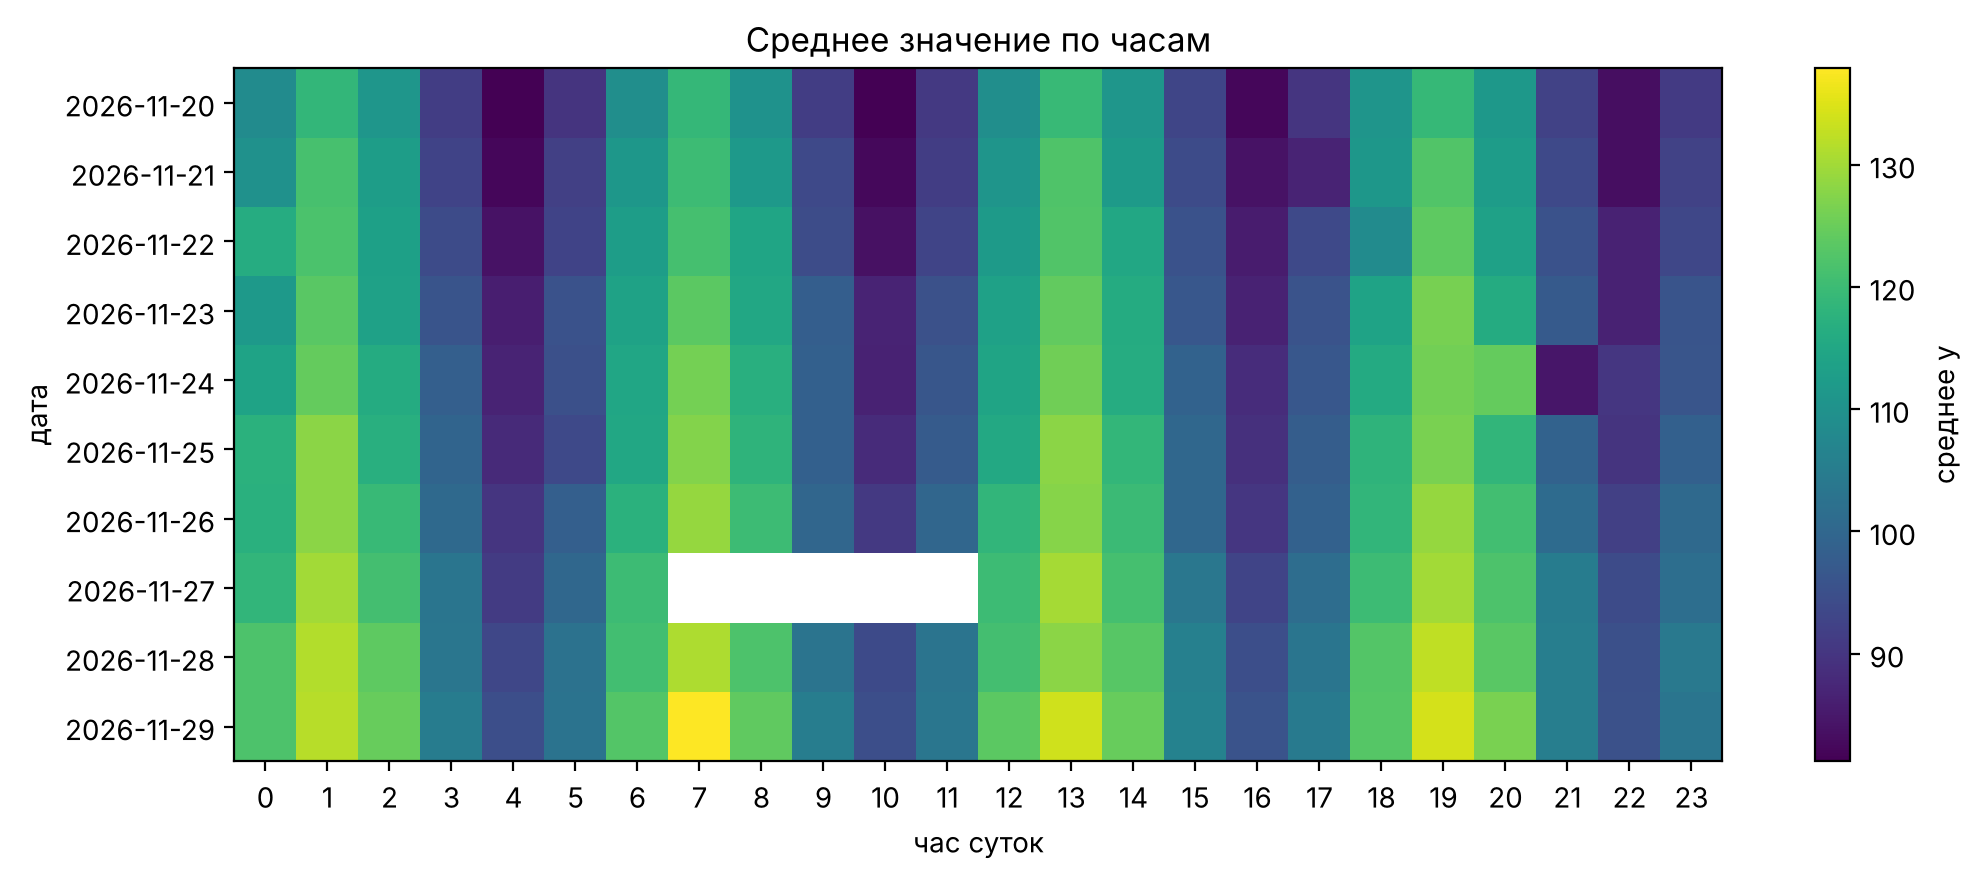

In [10]:
hm = df["y"].groupby([df.index.date, df.index.hour]).mean().unstack()
fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(hm.to_numpy(), aspect="auto", cmap="viridis")
ax.set_xticks(range(24)); ax.set_xticklabels(hm.columns)
ax.set_yticks(range(len(hm))); ax.set_yticklabels([str(d) for d in hm.index])
ax.set_xlabel("час суток"); ax.set_ylabel("дата"); ax.grid(False)
fig.colorbar(im, ax=ax, label="среднее y")
ax.set_title("Среднее значение по часам"); plt.show()

## 4. Пропуски

### 4.1 Сколько, где, есть ли длинные серии

In [11]:
def gap_runs(isna_arr):
    """Возвращает начала и концы (не включая) серий подряд идущих True."""
    padded = np.r_[False, np.asarray(isna_arr, dtype=bool), False]
    edges = np.flatnonzero(padded[1:] != padded[:-1])
    return edges[::2], edges[1::2]


isna = df["y"].isna()
starts, ends = gap_runs(isna.to_numpy())
gaps = pd.DataFrame({
    "начало": df.index[starts],
    "конец": df.index[ends - 1],
    "точек": ends - starts,
})
gaps["длительность, мин"] = gaps["точек"] * 5

print(f"Пропусков всего: {isna.sum()} из {len(df)} ({isna.mean():.1%})")
print(f"Серий пропусков: {len(gaps)}")
print(f"  одиночных (1 точка):  {(gaps['точек'] == 1).sum()}")
print(f"  короткие (2–12 точек): {gaps['точек'].between(2, 12).sum()}")
print(f"  длинные (>12 точек):  {(gaps['точек'] > 12).sum()}")
print(f"Самая длинная серия: {gaps['точек'].max()} точек = {gaps['точек'].max() * 5 / 60:.1f} ч\n")
print("Таблица пропусков (самые длинные серии):")
gaps.sort_values("точек", ascending=False).head(8).reset_index(drop=True)

Пропусков всего: 115 из 2880 (4.0%)
Серий пропусков: 42
  одиночных (1 точка):  38
  короткие (2–12 точек): 3
  длинные (>12 точек):  1
Самая длинная серия: 60 точек = 5.0 ч

Таблица пропусков (самые длинные серии):


,начало,конец,точек,"длительность, мин"
0,2026-11-27 07:00:00,2026-11-27 11:55:00,60,300
1,2026-11-24 20:40:00,2026-11-24 21:35:00,12,60
2,2026-11-21 17:40:00,2026-11-21 17:50:00,3,15
3,2026-11-27 21:50:00,2026-11-27 21:55:00,2,10
4,2026-11-20 13:10:00,2026-11-20 13:10:00,1,5
5,2026-11-22 05:25:00,2026-11-22 05:25:00,1,5
6,2026-11-22 12:50:00,2026-11-22 12:50:00,1,5
7,2026-11-21 04:20:00,2026-11-21 04:20:00,1,5


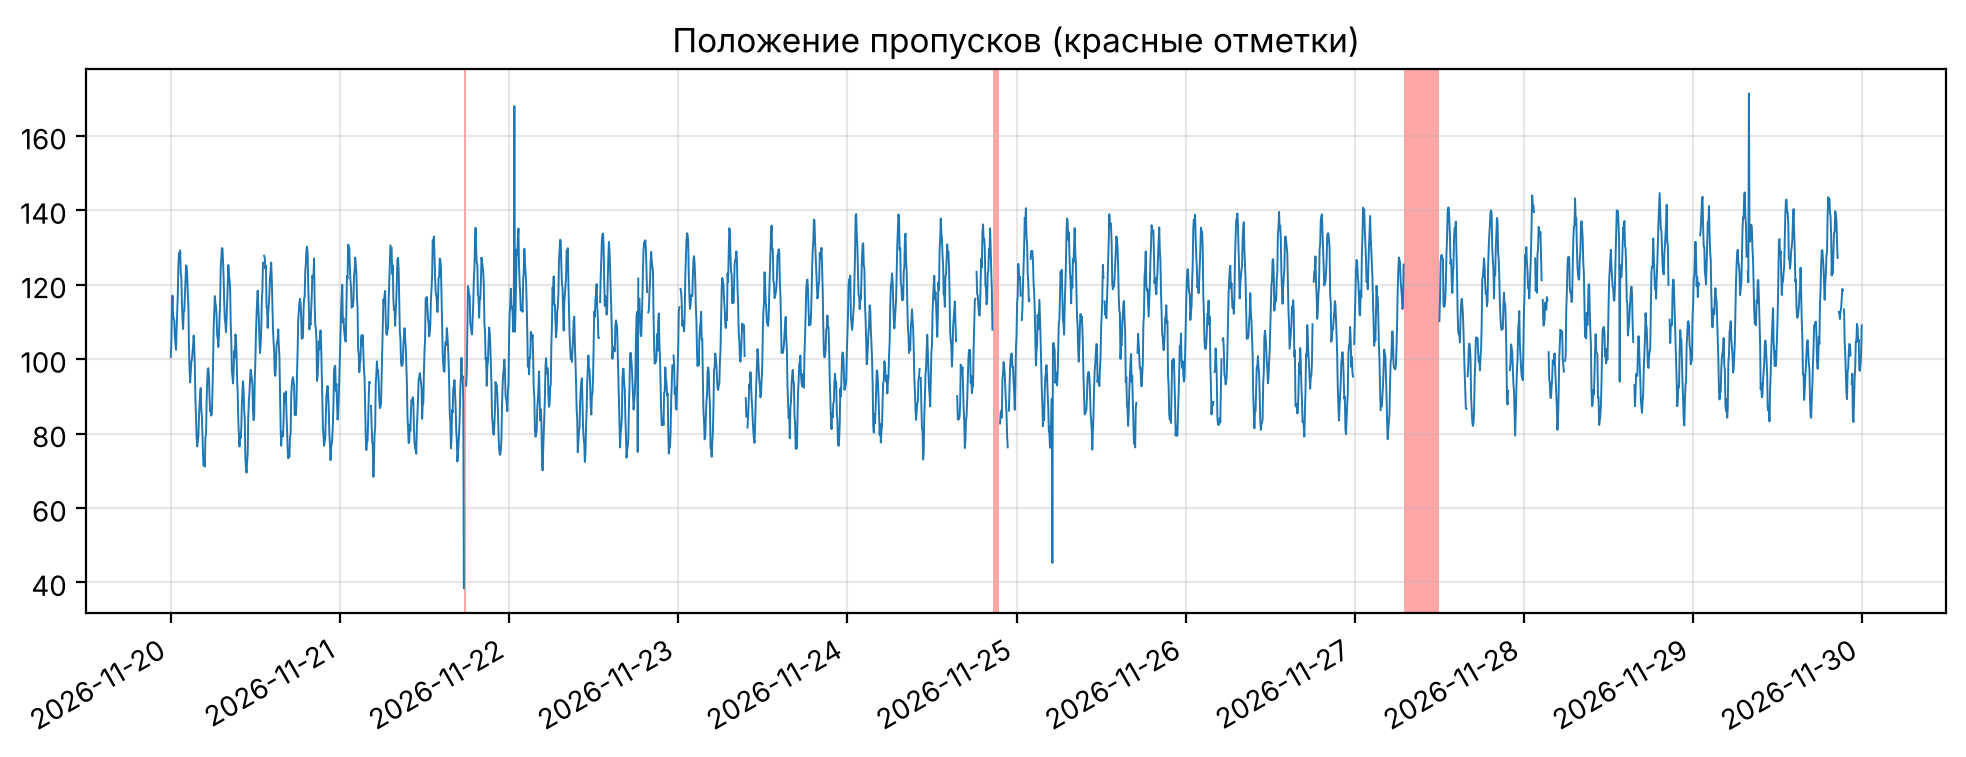

In [12]:
fig, ax = plt.subplots()
ax.plot(df.index, df["y"], lw=0.7)
for s, e in zip(starts, ends):
    ax.axvspan(df.index[s], df.index[e - 1], color="red", alpha=0.35, lw=0)
ax.set_title("Положение пропусков (красные отметки)"); fig.autofmt_xdate(); plt.show()

### 4.2 Методы импутации

Сравниваем четыре метода из лекции:
* **ffill** — перенос последнего значения вперёд;
* **linear** — линейная интерполяция;
* **median** — медиана всего ряда;
* **seasonal naive** — значение на один 6-часовой цикл (72 точки) раньше (если там пропуск — на цикл позже).

**Оценка качества на искусственно скрытых значениях.** Скрываем известные значения, восстанавливаем и считаем RMSE и MAE относительно настоящих.
Четыре сценария: 5% случайных одиночных точек, блок 15 минут (3 точки), блок 1 час (12 точек), блок 5 часов (60 точек). По 30 случайных повторов на сценарий.

Фильтр выбросов (скользящая медиана + MAD, он же метод детекции №3 в разделе 5) используется здесь в двух местах:
* скрываются только точки, не похожие на выбросы, иначе ошибка самих выбросов исказила бы сравнение;
* подозрительные точки не используются как опорные при заполнении: иначе выброс «тянется» в заполняемые места (например, сезонный наивный метод скопировал бы его через 6 часов).
Сами эти точки остаются в данных до раздела 5.

In [13]:
PERIOD = 72  # 6 часов


def robust_flags(s, window=9, thr=5.0):
    """Скользящая медиана + MAD остатков. Возвращает (флаги, базовая линия, робастный z)."""
    base = s.rolling(window, center=True, min_periods=window // 2 + 1).median()
    resid = s - base
    mad = (resid - resid.median()).abs().median()
    z = resid / (1.4826 * mad)
    return z.abs() > thr, base, z


def impute_ffill(s):
    return s.ffill().bfill()


def impute_linear(s):
    return s.interpolate(method="linear", limit_direction="both")


def impute_median(s):
    return s.fillna(s.median())


def impute_seasonal_naive(s, period=PERIOD):
    v = s.to_numpy(dtype=float)
    out = v.copy()
    n = len(v)
    for i in np.flatnonzero(np.isnan(v)):
        for k in range(1, n // period + 1):
            back, fwd = i - k * period, i + k * period
            if back >= 0 and not np.isnan(v[back]):
                out[i] = v[back]; break
            if fwd < n and not np.isnan(v[fwd]):
                out[i] = v[fwd]; break
    res = pd.Series(out, index=s.index)
    return res.interpolate(limit_direction="both")   # на случай, если ничего не нашлось


y = df["y"]
suspect, _, _ = robust_flags(y)   # точки, похожие на выбросы


def skip_suspects(f):
    """Не использовать подозрительные точки как опорные при заполнении (сами они остаются в данных)."""
    def g(s):
        out = f(s.mask(suspect))
        keep = suspect & s.notna()
        out[keep] = s[keep]
        return out
    return g


methods = {
    "ffill": skip_suspects(impute_ffill),
    "linear": skip_suspects(impute_linear),
    "median": skip_suspects(impute_median),
    "seasonal naive": skip_suspects(impute_seasonal_naive),
}

ok_arr = (y.notna() & ~suspect).to_numpy()
y_arr = y.to_numpy()


def make_mask(kind, rng):
    n = len(ok_arr)
    if kind == "single":
        cand = np.flatnonzero(ok_arr)
        m = np.zeros(n, dtype=bool)
        m[rng.choice(cand, size=int(0.05 * len(cand)), replace=False)] = True
        return m
    L = {"block 15 мин": 3, "block 1 час": 12, "block 5 часов": 60}[kind]
    while True:
        st = rng.integers(0, n - L)
        if ok_arr[st:st + L].all():
            m = np.zeros(n, dtype=bool); m[st:st + L] = True
            return m


def evaluate(kind, n_trials=30, seed=0):
    rng = np.random.default_rng(seed)
    errs = {name: [] for name in methods}
    for _ in range(n_trials):
        m = make_mask(kind, rng)
        s = y.copy(); s[m] = np.nan
        for name, f in methods.items():
            errs[name].append(f(s).to_numpy()[m] - y_arr[m])
    out = {}
    for name, e in errs.items():
        e = np.concatenate(e)
        out[name] = {"RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e))}
    return pd.DataFrame(out).T


kinds = ["single", "block 15 мин", "block 1 час", "block 5 часов"]
results = pd.concat({k: evaluate(k) for k in kinds}, axis=1).round(2)
results

single        block 15 мин       block 1 час         \
                 RMSE    MAE         RMSE   MAE        RMSE    MAE   
ffill            5.06   4.04         9.12   7.2       13.61  11.17   
linear           2.67   2.12         3.96   3.2       11.22   9.27   
median          16.22  13.65        16.22  13.5       17.04  14.35   
seasonal naive   2.89   2.30         2.83   2.3        2.67   2.13   

               block 5 часов         
                        RMSE    MAE  
ffill                  22.71  18.84  
linear                 20.97  17.15  
median                 16.55  13.88  
seasonal naive          2.71   2.13

### Наглядно: восстановление скрытых блоков в 1 час и 5 часов

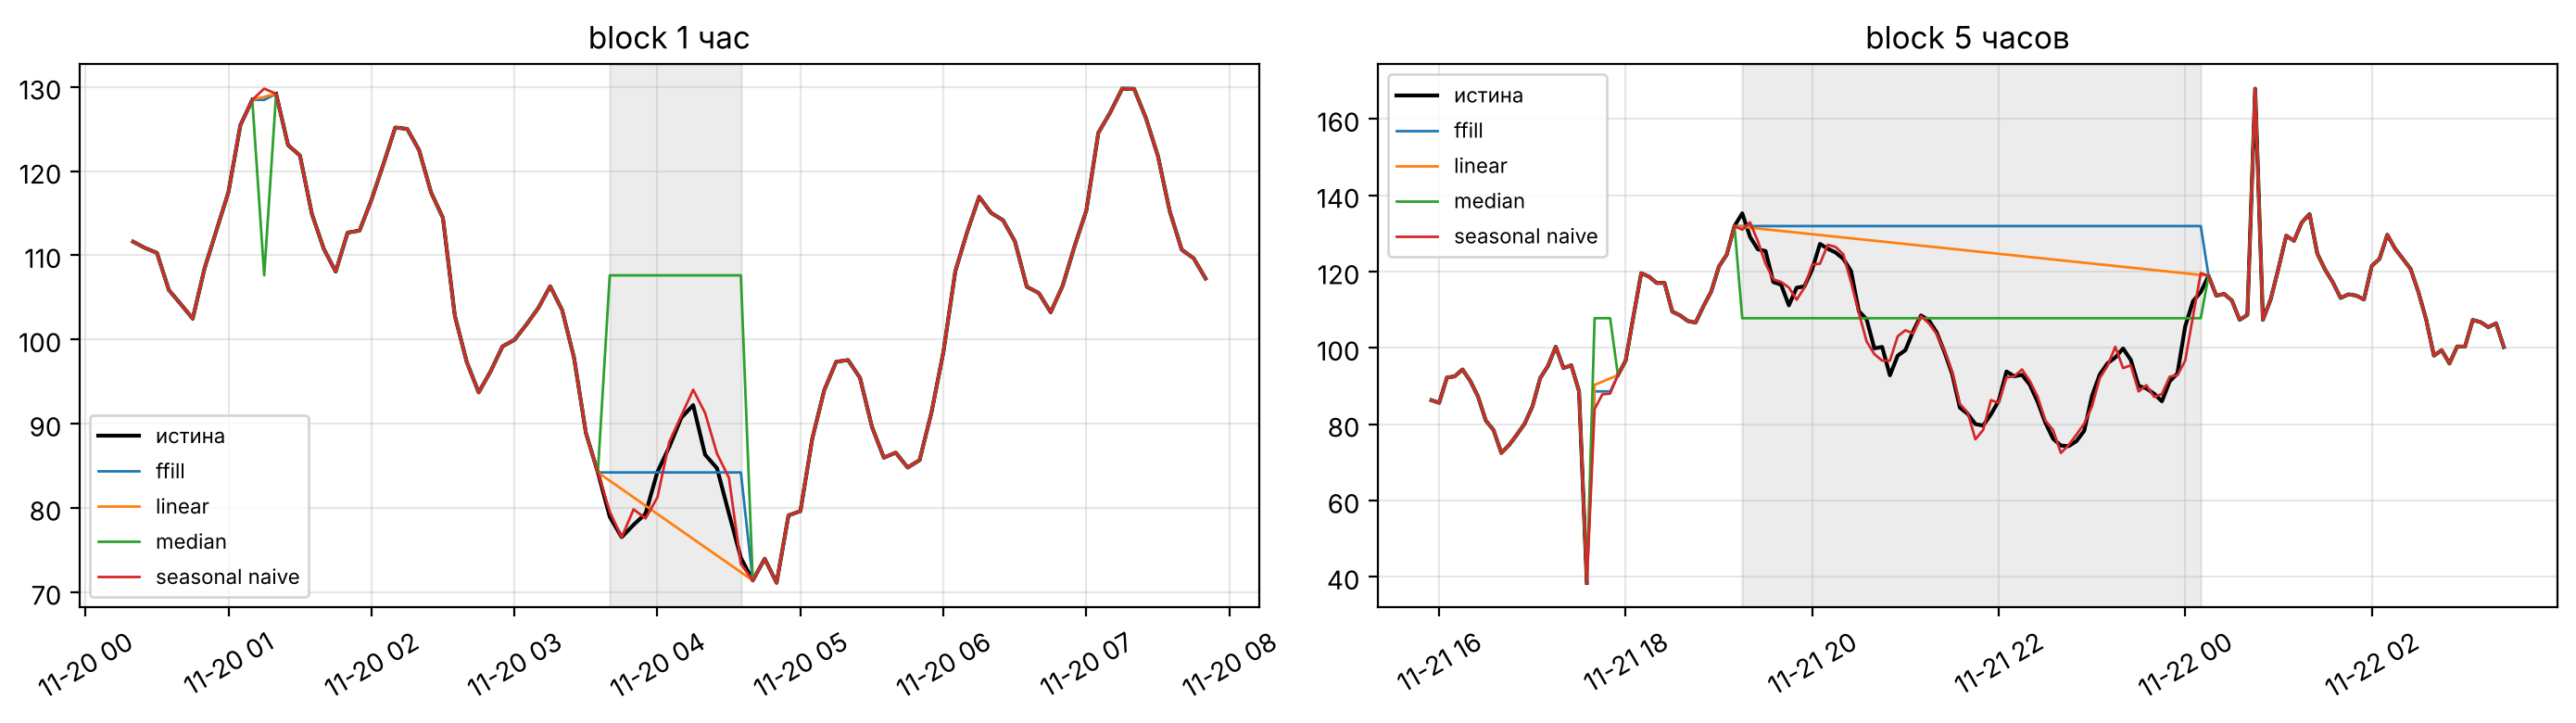

In [14]:
rng_demo = np.random.default_rng(123)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, kind in zip(axes, ["block 1 час", "block 5 часов"]):
    m = make_mask(kind, rng_demo)
    s = y.copy(); s[m] = np.nan
    i0, i1 = np.flatnonzero(m)[[0, -1]]
    lo, hi = max(i0 - 40, 0), min(i1 + 40, len(y))
    ax.plot(y.index[lo:hi], y.iloc[lo:hi], color="k", lw=1.5, label="истина")
    for name, f in methods.items():
        ax.plot(y.index[lo:hi], f(s).iloc[lo:hi], lw=1, label=name)
    ax.axvspan(y.index[i0], y.index[i1], color="gray", alpha=0.15)
    ax.set_title(kind); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 4.3 Заполнение реальных пропусков

Выбор по таблице выше: одиночные пропуски заполняем линейной интерполяцией (лучший RMSE в сценарии «single»), серии из двух и более точек — сезонным наивным методом (с блока в 15 минут он точнее).

Пропусков до: 115 | после: 0


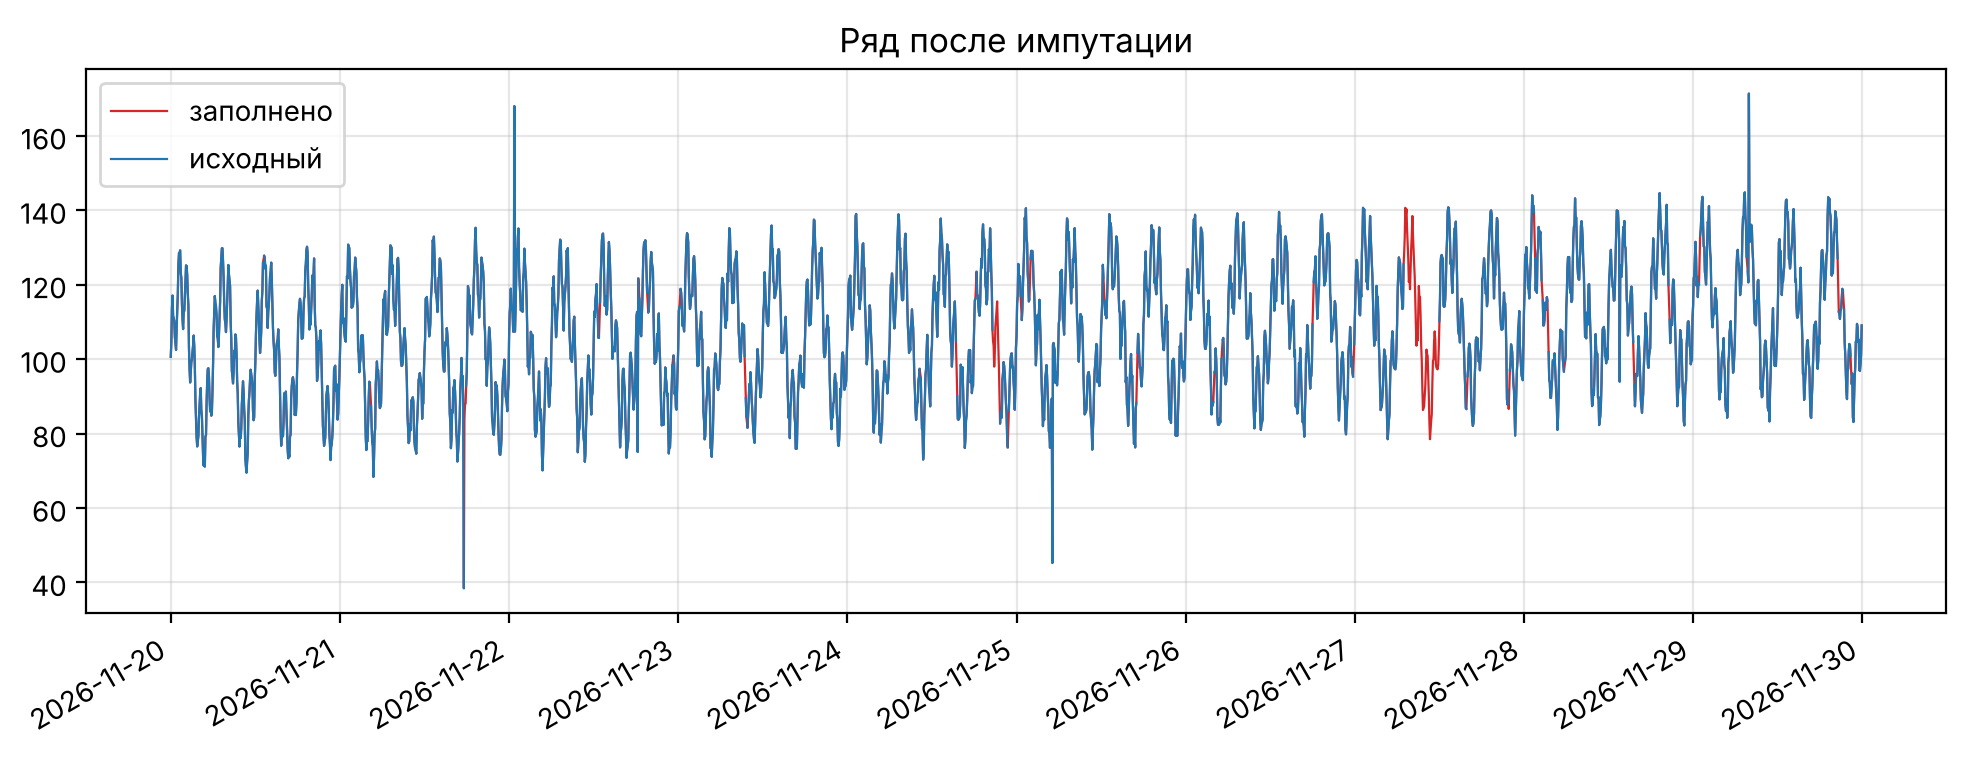

In [15]:
MAX_LINEAR_GAP = 1   # серии длиннее этого значения заполняем seasonal naive


def impute_hybrid(s, max_linear_gap=MAX_LINEAR_GAP):
    s_in = s.mask(suspect)                       # выбросы не используем как опорные точки
    lin, sn = impute_linear(s_in), impute_seasonal_naive(s_in)
    out = lin.copy()
    st, en = gap_runs(s.isna().to_numpy())       # серии считаем по исходным NaN
    for a, b in zip(st, en):
        if b - a > max_linear_gap:
            out.iloc[a:b] = sn.iloc[a:b]
    keep = suspect & s.notna()
    out[keep] = s[keep]                          # сами выбросы остаются до раздела 5
    return out


df["y_imp"] = impute_hybrid(df["y"])
print("Пропусков до:", df["y"].isna().sum(), "| после:", df["y_imp"].isna().sum())

fig, ax = plt.subplots()
ax.plot(df.index, df["y_imp"], color="C3", lw=0.8, label="заполнено")
ax.plot(df.index, df["y"], color="C0", lw=0.8, label="исходный")
ax.legend(); ax.set_title("Ряд после импутации"); fig.autofmt_xdate(); plt.show()

## 5. Выбросы

Три метода:
1. **IQR** (границы Q1 − 1.5·IQR, Q3 + 1.5·IQR) — как в лекции;
2. **z-score** (|z| > 3);
3. **скользящая медиана + MAD** (окно 9 точек = 45 минут, порог 5 робастных σ; влияние окна проверяем ниже).

Первые два применяются ко всему ряду сразу и не учитывают тренд и сезонность. Проверяем, насколько это важно.
Детекцию ведём только по реально наблюдавшимся точкам (заполненные пропуски не помечаем).

In [16]:
obs = df["y"].notna()
yo = df["y"]

# 1. IQR (как в лекции)
q1, q3 = yo.quantile([0.25, 0.75])
iqr = q3 - q1
df["outlier_iqr"] = (yo < q1 - 1.5 * iqr) | (yo > q3 + 1.5 * iqr)

# 2. z-score
z = (yo - yo.mean()) / yo.std()
df["outlier_z"] = z.abs() > 3

# 3. скользящая медиана + MAD
flags, base, zr = robust_flags(yo)
df["outlier_mad"] = flags & obs
df["baseline"] = base

def score(col):
    found = df.index[df[col]]
    tp = int(found.isin(true_outlier_ts).sum())
    return {"найдено": len(found), "верных": tp, "ложных": len(found) - tp,
            "пропущено": int((~true_outlier_ts.isin(found)).sum())}

table = pd.DataFrame({
    "IQR": score("outlier_iqr"),
    "z-score": score("outlier_z"),
    "скользящая медиана + MAD": score("outlier_mad"),
}).T
print(f"Истинных выбросов (для проверки): {len(true_outlier_ts)}\n")
table

Истинных выбросов (для проверки): 6



,найдено,верных,ложных,пропущено
IQR,4,4,0,2
z-score,4,4,0,2
скользящая медиана + MAD,6,6,0,0


In [17]:
sens = {}
for w in (7, 9, 13):
    fl, _, _ = robust_flags(yo, window=w)
    fnd = df.index[fl & obs]
    sens[f"окно {w}"] = {"найдено": len(fnd), "верных": int(fnd.isin(true_outlier_ts).sum()),
                         "ложных": int((~fnd.isin(true_outlier_ts)).sum())}
print("Чувствительность метода 3 к размеру окна (порог 5):")
pd.DataFrame(sens).T

Чувствительность метода 3 к размеру окна (порог 5):


,найдено,верных,ложных
окно 7,182,6,176
окно 9,6,6,0
окно 13,2,2,0


In [18]:
found = df[df["outlier_mad"]].copy()
found["отклонение от базы"] = found["y"] - found["baseline"]
found["изолирован"] = [not (df["outlier_mad"].shift(1).fillna(False).loc[t] or df["outlier_mad"].shift(-1).fillna(False).loc[t]) for t in found.index]
found["истинный выброс"] = found.index.isin(true_outlier_ts)
found[["y", "baseline", "отклонение от базы", "изолирован", "истинный выброс"]].round(1)

,y,baseline,отклонение от базы,изолирован,истинный выброс
timestamp,,,,,
2026-11-21 17:35:00,38.5,93.8,-55.3,True,True
2026-11-22 00:45:00,168.0,112.8,55.2,True,True
2026-11-22 18:15:00,75.0,111.2,-36.1,True,True
2026-11-25 05:05:00,45.2,89.4,-44.1,True,True
2026-11-28 13:35:00,93.9,125.2,-31.3,True,True
2026-11-29 07:55:00,171.3,132.7,38.6,True,True


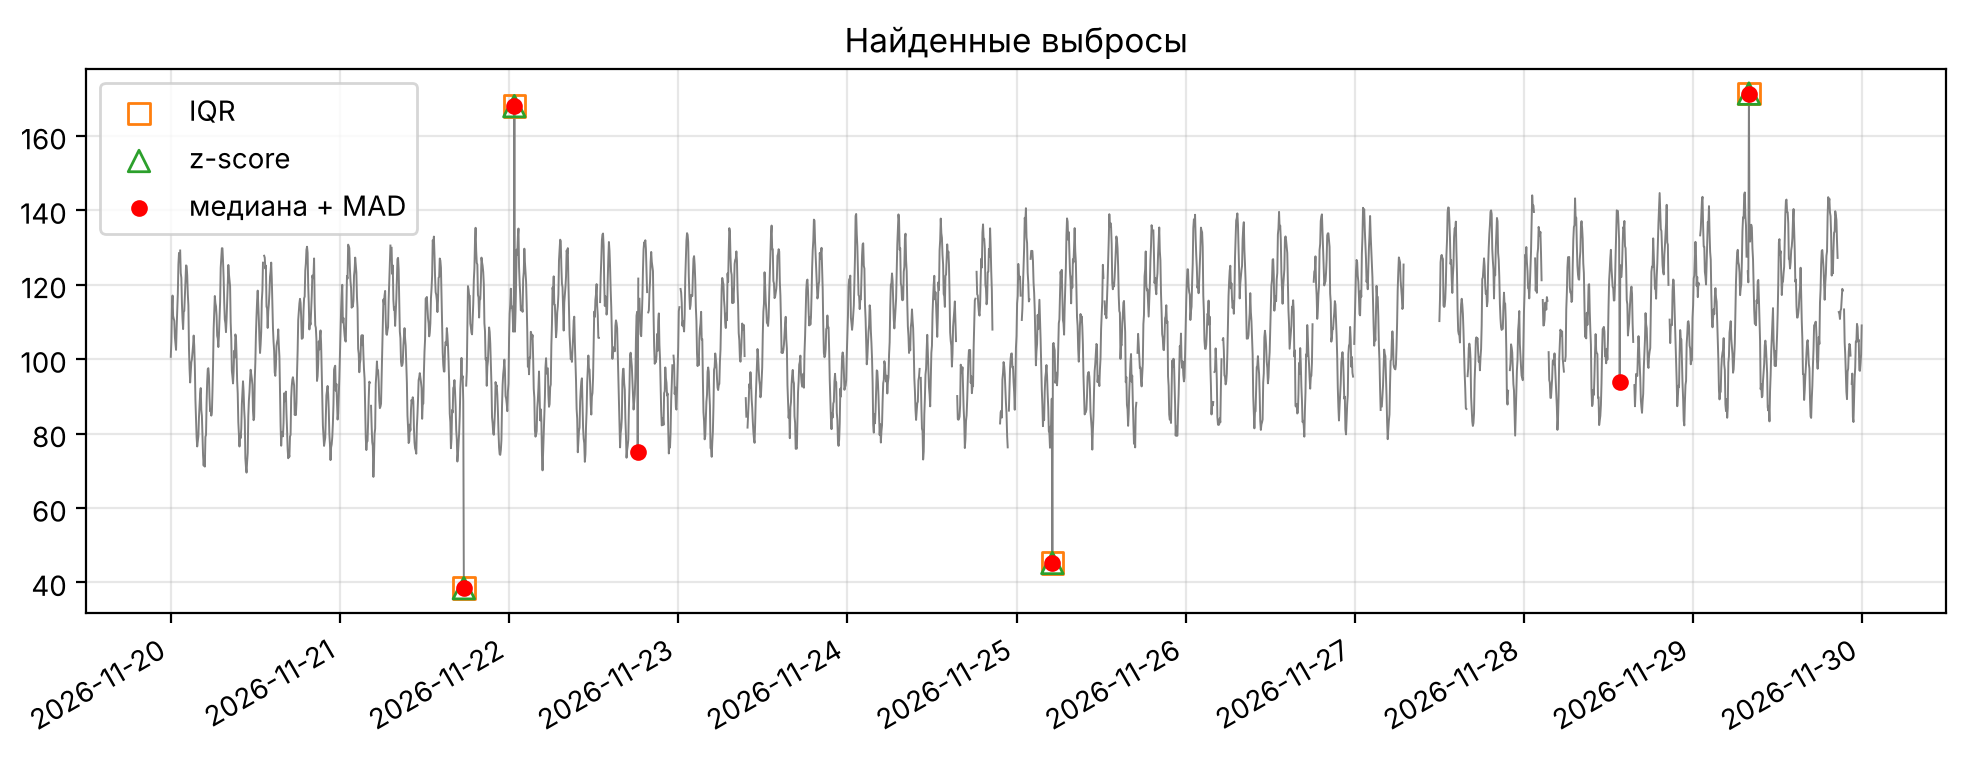

In [19]:
fig, ax = plt.subplots()
ax.plot(df.index, df["y"], lw=0.7, color="gray")
for col, c, mk, lab in [("outlier_iqr", "C1", "s", "IQR"), ("outlier_z", "C2", "^", "z-score")]:
    ax.scatter(df.index[df[col]], df.loc[df[col], "y"], s=60, facecolors="none", edgecolors=c, marker=mk, label=lab, zorder=3)
ax.scatter(df.index[df["outlier_mad"]], df.loc[df["outlier_mad"], "y"], s=25, color="red", label="медиана + MAD", zorder=4)
ax.legend(); ax.set_title("Найденные выбросы"); fig.autofmt_xdate(); plt.show()

### Ошибка или реальное событие?

Все найденные точки — одиночные скачки на десятки единиц при σ шума ≈ 2, после которых ряд сразу возвращается на прежний уровень.
Это похоже на сбой датчика/ошибку записи, а не на реальное событие: настоящее событие обычно держится несколько точек или меняет уровень.
Для реальных данных решение принимается с участием специалиста предметной области. Здесь выбросы заменяются значением скользящей медианы (в `y_clean`), а исходный столбец `y` сохраняется.

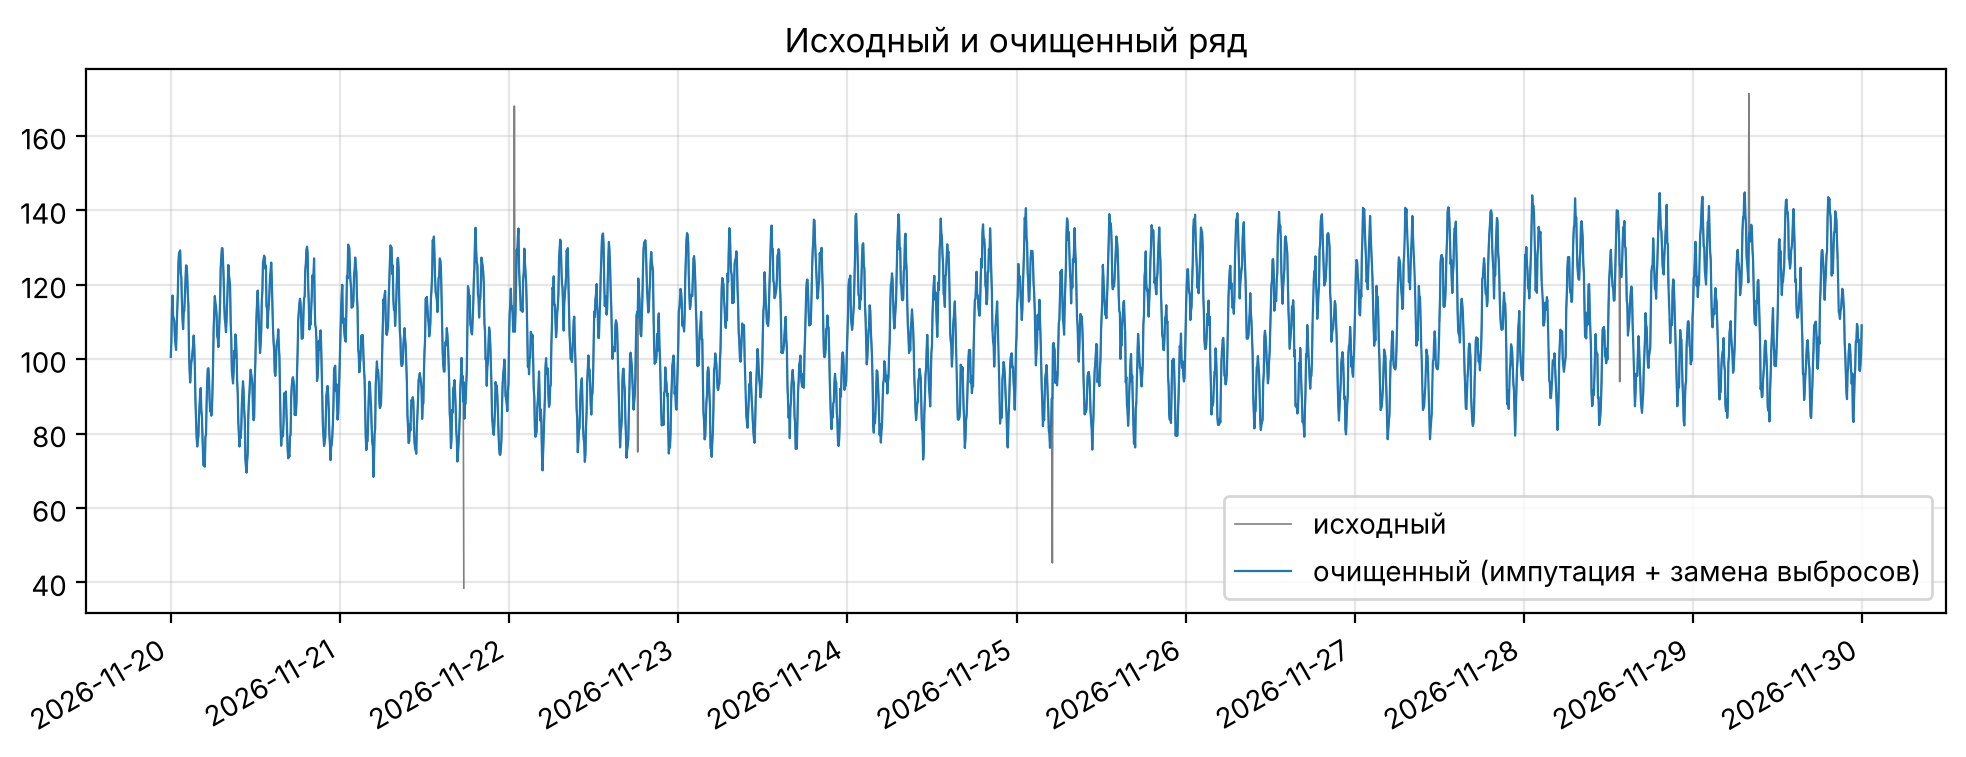

NaN в y_clean: 0


In [20]:
df["y_clean"] = df["y_imp"].where(~df["outlier_mad"], df["baseline"])

fig, ax = plt.subplots()
ax.plot(df.index, df["y"], lw=0.6, color="gray", label="исходный")
ax.plot(df.index, df["y_clean"], lw=0.8, color="C0", label="очищенный (импутация + замена выбросов)")
ax.legend(); ax.set_title("Исходный и очищенный ряд"); fig.autofmt_xdate(); plt.show()
print("NaN в y_clean:", df["y_clean"].isna().sum())

## 6. Выводы

**Основные выводы по ряду**

1. **Тренд есть, он растущий и примерно линейный.** Среднесуточное значение растёт со 100.5 до 114.3 (+13.8 за 10 суток, около +1.5 в сутки). Суточные средние выбраны намеренно: за сутки обе сезонности сокращаются.
2. **Сезонностей две.** Короткая — 1 час (колебание в профиле внутри часа около ±8), длинная — 6 часов (колебание в профиле цикла около ±29, это главная часть разброса ряда). На heatmap пики стабильно повторяются в 1, 7, 13 и 19 часов каждые сутки.
3. **Дисперсия постоянна, структурных сдвигов нет.** Скользящее std держится около 16 (5–95% квантили: 15.3–17.8) без тенденции. Этот уровень задаёт в основном сезонность, а не шум (σ шума ≈ 2).
4. **Пропуски:** 115 из 2880 точек (4.0%) в 42 сериях: 38 одиночных, 3 короткие (2, 3 и 12 точек) и одна длинная (60 точек = 5 часов, 27.11 с 07:00). Для одиночных точек лучше линейная интерполяция (RMSE 2.67 против 2.89). Начиная с блока в 15 минут точнее сезонный наивный метод: RMSE 2.83 / 2.67 / 2.71 для блоков 15 минут / 1 час / 5 часов против 3.96 / 11.22 / 20.97 у линейной интерполяции. `ffill` и медиана хуже везде (RMSE медианы около 16).
5. **Выбросы:** 6 одиночных скачков на 31–55 единиц от базовой линии, после каждого ряд сразу возвращается к норме, то есть это похоже на сбои датчика. IQR и z-score нашли только 4 из 6: границы считаются по всему ряду, а он и без выбросов широкий из-за сезонности и тренда, поэтому слабые скачки остаются «внутри нормы». Скользящая медиана + MAD нашла все 6 без ложных срабатываний.

**Проблемы качества данных (в порядке обнаружения)**

* Файл не отсортирован по времени.
* 3 дубликата `timestamp`.
* Нерегулярная сетка: 115 отсутствующих отсчётов (в том числе серия 5 часов).
* 6 выбросов, похожих на ошибки записи.

**Ограничения и оговорки**

* Ряд синтетический, истинные значения и позиции выбросов известны. Это позволило честно оценить импутацию и детекцию, но в реальных данных такой разметки нет.
* Метод №3 очень зависит от окна: при окне 7 точек — 176 ложных срабатываний, при окне 13 пропущено 4 выброса из 6. Окно 9 и порог 5 подбирались на этих данных, для другого ряда их нужно проверять заново.
* Фильтр выбросов используется при оценке импутации (скрываются только «нормальные» точки, подозрительные не служат опорными). Без этого сезонный наивный метод копировал бы выбросы через 6 часов.
* Решение «выброс — это ошибка или реальное событие» для реальных данных принимается вместе со специалистом предметной области.
